# Finding the minima of variational free energy by coordinate search

This notebook demonstrates how to use variational free energy of a loss function and how to find the minima of variational free energy using a simple coordinate search procedure.

==========================================================================

* **Notebook dependencies**:
    * ...

* **Content**: Jupyter notebook accompanying Chapter 4 of the textbook "Fundamentals of Active Inference"

* **Author**: Sanjeev Namjoshi (sanjeev.namjoshi@gmail.com)

* **Version**: 0.1

In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import os
import sys

from scipy.stats import norm

module_path = os.path.abspath(os.path.join(os.pardir, os.pardir))
if module_path not in sys.path:
    sys.path.append(module_path)

from src.maths import loge
from src.utils import create_agent

mpl.style.use("seaborn-deep")

/tmp/ipykernel_272909/3060845326.py:16: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  mpl.style.use("seaborn-deep")


Bayes' theorem, introduced in Chapters 1 and 2, is written as follows:

$$
p(x \mid y) = \frac{p(y \mid x)p(x)}{p(y)}
$$

The generative model $p(x, y)$ is composed of the product of the likelihood and prior: 

$$
p(x, y) = p(y \mid x)p(x)
$$

The denominator in Bayes' theorem, $p(y)$ may be obtained by marginalizing out $x$ from the generative model:

$$
p(y) = \sum_x p(x, y)
$$

If we let $Z = p(y)$ then we can write Bayes' theorem in the following way:

$$
p(x \mid y) = \frac{p(x, y)}{\sum_x p(x, y)} = \frac{p(x, y)}{Z}
$$

It turns out that $Z$ is a **normalization constant** or more generally, a **constant of proportionality**. To see this, let's set up a simple generative model which is the same one explored in many examples in Chapter 2. 

## Variational free energy and coordinate search

It turns out that computing $Z$ is generally computationally expensive or intractable which precludes us from finding the posterior easily. One solution to this is to resort to optimization where the loss function is variational free energy. 

As explained in Chapter 4, in fixed-form variational inference, the minima of variational free energy corresponds to the optimal values for the mean and variance of the posterior distribution. Formally, this means our optimization requires us to perform the following:

$$
    p(x \mid y) \approx \underset{\mu_x, \sigma^2_x}{\text{argmin}} \hspace{1mm} \mathcal{F} \left [\mu_x, \sigma^2_x \right ]
$$

where $\mathcal{F}$ is variational free energy.

Variational free energy has a number of different forms as explained in the next notebook. Here we will use the $\textbf{G} - \text{form}$ of variational free energy which has the following formula:

$$
    \mathcal{F} = \int q(x) \log \frac{q(x)}{p(x, y)} dx
$$

As we can see, this formula relies upon two inputs:
* An approximate posterior $q(x)$ that specifies our current running best guess of the true posterior. At each iteration of free energy minimization we will receive new updates for the mean and variance of $q(x)$ which will allow us to generate the full distribution of $q(x)$, an approximation to the posterior.
* The generative model $p(x, y = \hat{y})$ after we receive the data. While $q(x)$ will update at each iteration of gradient descent, the generative model will remain fixed. This is like saying: "Now that our model has seen that data let's keep the model fixed and then update $q(x)$ based on this fixed model".

Note that since the generative model is fixed (its probability distributions will not change during variational inference) the part of the generative model that will change is $q(x)$. Under fixed-form assumptions ($q(x)$ is assumed to be Gaussian), the only things that will be optimized will be the mean and variance of $q(x)$.

We can represent variational free energy in code as follows:

In [2]:
def F_g(q, pxy):
    return np.sum(q * (loge(q) - loge(pxy)))

As explained in Chapter 4 (Figure 4.2 and Example 4.1), we will be finding the minima of VFE with coordinate search. Recall that since variational free energy is meant to optimize in parameter space (the mean and variance of $q(x)$), each step on the VFE loss function represents a step toward a different coordinate pair of (mean, variance). Thus, according to coordinate search (Figure 4.2), we have eight possible direction to step (or nine if we include staying in place). We can encapsulate this in the following coordinate descent function:

In [3]:
def coordinate_descent(mu_q, var_q, pxy, x_range, kappa=0.01):
    
    # Potential eight coordinates of mu_q and var_q
    coordinates = [
        [mu_q - kappa, var_q + kappa], [mu_q, var_q + kappa], [mu_q + kappa, var_q + kappa],
        [mu_q - kappa, var_q        ], [mu_q, var_q        ], [mu_q + kappa, var_q        ],
        [mu_q - kappa, var_q - kappa], [mu_q, var_q - kappa], [mu_q + kappa, var_q - kappa]
    ]
    
    # Loop over options and calculate vfe for each
    vfe = []
    for c in coordinates:
        q = norm.pdf(x_range, loc=c[0], scale=c[1])
        vfe.append(F_g(q, pxy))
    
    # Get index for mean-variance coordinate pari with minimum VFE and select it
    min_idx = np.argmin(vfe)
    update = coordinates[min_idx] 
    
    return update[0], update[1]

This code defines the nine possible places to step along the variational free energy loss given a step size of $\kappa$. Each one of these positions represents a new mean or variance under consideration corresponding to nine possible shapes for $q(x)$. We want to step in the direction of the (mean, variance) pair that minimizes variational free energy. Then, we choose this mean and variance as our update to represent our current best guess of $q(x)$. 

## Creating the agent and running variational inference

Next, we will create an agent, pass the data to its generative model, and perform variational inference to obtain the posterior iteratively. In the code below we use the pre-built agent with a linear model that relates states to observations. Instead of generating data from the environment we will assume that the data is already available ($\hat{y} = 7$).

In [4]:
# Agent parameters
agent_params = {
    "beta_0" : 3,    # Linear parameter intercept
    "beta_1" : 2,    # Linear parameter slope
    "std_y"  : 0.5,  # Likelihood standard deviation
    "m_x"   : 4,     # Prior mean
    "s_x"  : 0.5,    # Prior standard deviation
    "x_range": np.linspace(start=0.01, stop=5, num=500)
}

# Create agent
agent = create_agent(name="exact_linear", params=agent_params)

# Run agent
y = 7.                # Data input
agent.build(y)        # Build the generative model

Now we create empty arrays to store the history so we can plot it and examine it later.

In [5]:
x_range = agent.params.x_range                      # Range of x under consideration
x_points = int(np.max(x_range) / np.min(x_range))   # Total points in grid approximation

J          = 20                       # Set the maximum number of iterations
q          = np.zeros((J, x_points))  # Initialize empty variational density (q) for each iteration
mu_q       = np.zeros(J)              # Initialize empty q mean for each iteration
var_q      = np.zeros(J)              # Initialize empty q variance for each iteration
vfe        = np.zeros(J)              # Initialize variational free energy for each iteration

Next, we initialize $q(x)$ by assuming that it starts equal to the prior. We then calculate the variational free energy for this initialization of $q(x)$ given our generative model.

In [6]:
prior       = agent.prior
prior_mean  = agent.params.m_x
prior_noise = agent.params.s_x
pxy         = agent.model

q[0]     = prior            # Initialize variational density with prior
mu_q[0]  = prior_mean       # Initialize q mean with prior mean
var_q[0] = prior_noise      # Initialize q variance with prior variance
vfe[0]   = F_g(q[0], pxy)   # Initialize variational free energy

And finally we can run the coordinate search procedure. Here we run coordinate search on the current mean and variance of $q(x)$ given the generative model `pxy` and a learning rate, $\kappa$. The result of the update is a new mean and variance which represents our current best guess about these parameters. The next line uses this new mean and variance to compute the PDF for $q(x)$ representing our current approximation to the posterior. Finally, we calculate VFE.

Although we could examine VFE to determine when convergence has been reached (when VFE flatlines and becomes time invariant), instead we will simply cut the simulation short after `J=20` iterations.

In [7]:
for j in range(J-1):
    mu_q[j+1], var_q[j+1]           = coordinate_descent(mu_q[j], var_q[j], pxy, x_range, kappa=0.1)
    q[j+1]                          = norm.pdf(x_range, loc=mu_q[j+1], scale=var_q[j+1])
    vfe[j+1]                        = F_g(q[j+1], pxy)

Here is a visualization of the coordinate descent process from initialization to convergence at the minima of the variational free energy loss function.

Text(0, 0.5, 'VFE')

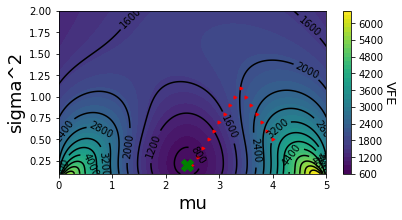

In [8]:
# Function to vectorize to compute full VFE loss for mu and sigma parameter ranges
def vfe_over_parameters(mu, sigma):
    q = norm.pdf(x_range, loc=mu, scale=sigma)
    return F_g(q, pxy)

fig, ax = plt.subplots(1,1, facecolor=(1,1,1), figsize=(6, 3))

# Set up grid
mu_range = np.linspace(0, 5, 200)
sigma_range = np.linspace(0.1, 2, 200)
X, Y = np.meshgrid(mu_range, sigma_range)

# Vectorize NLL and compute the costs at all combinations of beta_0 and beta_1
vfe_param_vec = np.vectorize(vfe_over_parameters)
z = vfe_param_vec(X, Y)

# Plot the contours of the costs and fill them in
contours = ax.contour(X, Y, z, levels=15, colors='k')
fill = ax.contourf(X, Y, z, levels=50, cmap="viridis")

# Plot the beta_0 and beta_1 updates across the loss function
ax.plot(mu_q, var_q, "r>", ms=3)
ax.plot(2.4, 0.2, marker="X", color="green", markersize=12)   # True parameters

# Axis labels
ax.set_xlabel("mu", fontsize=18)
ax.set_ylabel("sigma^2", fontsize=18)

# Labels contours and add colorbar
plt.clabel(contours)
cbar = plt.colorbar(fill)
cbar.ax.get_yaxis().labelpad = 12
cbar.ax.set_ylabel("VFE", rotation=270, fontsize=13)

Likewise, we may also view the full distribution of $q(x)$ at each parameter setting selected over the course of coordinate search.

/tmp/ipykernel_272909/4256620518.py:16: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(sm, ticks=np.linspace(0,J,5))


<Figure size 432x288 with 0 Axes>

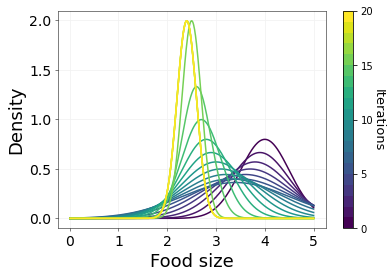

In [9]:
fig = plt.figure()
fig, ax = plt.subplots(1,1, facecolor=(1,1,1))

cmap = plt.get_cmap('viridis',J)

for j in range(J):
        ax.plot(x_range, q[j], c=cmap(j))

# Axis labels and styling
ax.set_xlabel("Food size", fontsize=18)
ax.set_ylabel("Density", fontsize=18)

norm_col = mpl.colors.Normalize(vmin=0,vmax=J)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm_col)
sm.set_array([])
cbar = plt.colorbar(sm, ticks=np.linspace(0,J,5))

cbar.ax.get_yaxis().labelpad = 12
cbar.ax.set_ylabel("Iterations", rotation=270, fontsize=13)

# Axis style
ax.axes.grid(which="major", axis="both", c="#f2f2f2")
plt.setp(ax.spines.values(), color="black", linewidth=0.5)
ax.tick_params(
    labelsize=14,
    axis='both',          
    which='major',      
    bottom=True,
    left=True,
    color="black",
    width=0.5,
    length=3)